# Nepal Hydropower Projects: Data Analysis and Visualization

**Objective:** clean, transform and explore the Nepal hydropower licence dataset, then turn the findings into
insights that can guide decisions.

**Workflow**

1. Data collection and exploration
2. Data cleaning and transformation (missing values, outliers, dates, feature engineering, encoding, scaling)
3. Exploratory data analysis (descriptive statistics, distributions, relationships, correlations)
4. Feature selection
5. Key insights and recommendations

**Dataset:** `hydropower.csv`, 572 licence records and 14 columns (project, province, district, municipality,
capacity in MW, river, licence number, issue date, validity, promoter, address, coordinates, licence type).

> **How to run:** put `hydropower.csv` in the `data/` folder (or next to this notebook) and use *Run All*.
> Cleaned data is written to `data/` and every figure is saved to `figures/`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42

# Folder layout: works from the repo root, from notebooks/, or from Google Colab
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR, FIG_DIR = ROOT / "data", ROOT / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)


def find_raw_file():
    """Look for the raw CSV in the usual places."""
    for p in [DATA_DIR / "hydropower.csv", Path("hydropower.csv"), Path("/content/hydropower.csv")]:
        if p.exists():
            return p
    raise FileNotFoundError("hydropower.csv not found. Place it in the data/ folder.")


def save_fig(name):
    """Tidy layout, save the current figure to figures/ and display it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Data Collection and Exploration

### 1.1 Load the dataset

In [2]:
df_raw = pd.read_csv(find_raw_file())   # untouched copy of the source data
df = df_raw.copy()                       # all cleaning happens on this copy
df.head()

,Project,Province,District,Municipality,Capacity (MW),River,Lic No,Isuue Date,Validity,Promoter,Address,Longitude,Latitude,License Type
0,Aayu Chhatigad Hydropower Project,Province 7,DARCHULA,Apihimal,13.942,Chatti Gad,798,12/21/2073,12/20/2075,Puwa Khola-1 Hydro Power Pvt.Ltd.,"Anamnagar-32,Kathmandu,Nepal. GPO 20863, 41027...",80.881528,29.820139,Survey
1,Aayu Malun Khola Hydro-Electric Project,Province 1,SOLUKHUMBU,Solududhakunda,21.000,Malun,807,1/15/2074,1/14/2076,Puwa Khola-1 Hydropower Private Limited,"Anamnagar-32, Kathmandu Nepal",86.425556,27.376944,Survey
2,Adhikhola Storage HEP,Province 5,PALPA,Bagnaskali,180.000,Adhikhola,821,2/4/2074,2/3/2076,Nepal Electricity Authority,"Nepal Electricity Authority, Central Office Du...",83.666667,27.950000,Survey
3,Akhu Khola-2 HPP,Province 4,GORKHA,Aarughat,20.000,Akhu Khola,749,7/29/2073,7/28/2075,Gorakshya Hydropower Pvt. Ltd.,"House no.319,Babarmahal, Kathmandu, 4219730,42...",84.962639,28.040139,Survey
4,Andhi Khola,Province 4,SYANGJA,Bhirkot,9.400,Andhi Khola,2_gtd,1/8/2052,12/30/2101,Butwal Power Company,0,83.680972,27.938333,Operation


### 1.2 Structure, data types and summary statistics

In [3]:
print("Rows, columns:", df.shape)
print("\nColumns:", df.columns.tolist())
print()
df.info()

Rows, columns: (572, 14)

Columns: ['Project', 'Province', 'District', 'Municipality', 'Capacity (MW)', 'River', 'Lic No', 'Isuue Date', 'Validity', 'Promoter', 'Address', 'Longitude', 'Latitude', 'License Type']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 572 entries, 0 to 571
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Project        572 non-null    object 
 1   Province       572 non-null    object 
 2   District       572 non-null    object 
 3   Municipality   572 non-null    object 
 4   Capacity (MW)  572 non-null    float64
 5   River          572 non-null    object 
 6   Lic No         572 non-null    object 
 7   Isuue Date     572 non-null    object 
 8   Validity       572 non-null    object 
 9   Promoter       572 non-null    object 
 10  Address        572 non-null    object 
 11  Longitude      572 non-null    float64
 12  Latitude       572 non-null    float64
 13  License Type   5

In [4]:
# Summary statistics for numeric and text columns
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Project,572,569,Phalakhu Khola HPP,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Province,572,6,Province 4,182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,572,54,DOLAKHA,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Municipality,572,186,Madi,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Capacity (MW),572.0,NaN,NaN,NaN,41.911152,124.863001,0.1,4.2,9.229,26.25,1902.0
River,572,315,Seti Khola,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Lic No,572,512,0,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Isuue Date,572,382,12/6/2051,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Validity,572,381,0/1/0,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Promoter,572,511,Nepal Electricity Authority,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.3 Data-quality checks

The raw data has no `NaN` values, but that does not mean it is clean. Missing information is often hidden behind
**placeholder values** (such as `0`), so we check for exact duplicates, repeated identifiers, impossible values
and suspicious "most frequent" values.

In [5]:
print("Missing values (NaN):", int(df.isnull().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate project names:", int(df["Project"].duplicated().sum()))
print("Repeated licence numbers:", int(df["Lic No"].duplicated().sum()))

# Impossible or suspicious numeric values (Nepal lies roughly between 80-89 E and 26-31 N)
print("\nCapacity <= 0:", int((df["Capacity (MW)"] <= 0).sum()))
print("Longitude outside Nepal:", int((~df["Longitude"].between(80, 89)).sum()))
print("Latitude outside Nepal:", int((~df["Latitude"].between(26, 31)).sum()))

Missing values (NaN): 0
Exact duplicate rows: 0
Duplicate project names: 3
Repeated licence numbers: 60

Capacity <= 0: 0
Longitude outside Nepal: 0
Latitude outside Nepal: 0


In [6]:
# Look for placeholder values hiding behind "duplicates" and in text columns
for col in ["Lic No", "Address", "Validity", "Isuue Date"]:
    print(f"--- {col}: most frequent values ---")
    print(df[col].value_counts().head(3).to_string(), "\n")

print("Repeated project names:")
display(df[df["Project"].duplicated(keep=False)].sort_values("Project")[["Project", "District", "Capacity (MW)", "License Type", "Lic No"]])

--- Lic No: most frequent values ---
Lic No
0        48
1_gtd    12
1023      2 

--- Address: most frequent values ---
Address
0                          42
Kathmandu                   7
Durbar Marg , Kathmandu     4 

--- Validity: most frequent values ---
Validity
0/1/0         40
11/30/2101    15
7/22/2076      5 

--- Isuue Date: most frequent values ---
Isuue Date
12/6/2051    12
0/1/0        11
2/9/2075      7 

Repeated project names:


,Project,District,Capacity (MW),License Type,Lic No
103,Ghunsa Khola HPP,TAPLEJUNG,155.82,Survey,991
104,Ghunsa Khola HPP,TAPLEJUNG,71.50,Survey,737
324,Phalakhu Khola HPP,RASUWA,5.00,Generation,161
325,Phalakhu Khola HPP,RASUWA,14.70,Generation,162
382,Seti Khola HPP,KASKI,30.00,Survey,803
383,Seti Khola HPP,PARBAT,3.50,Generation,205


**Issues found**

| Issue | Evidence | Planned treatment |
|---|---|---|
| Placeholder licence numbers | `Lic No` = `0` (48 rows) and `1_gtd` (12 rows) cause the 60 "duplicate" licence numbers | Convert to missing, label `Unknown` |
| Placeholder addresses | `Address` = `0` (42 rows) | Convert to missing, label `Unknown` |
| Placeholder validity | `Validity` = `0/1/0` (40 rows) is not a date | Convert to missing |
| Dates stored as text | `Isuue Date` (typo) and `Validity` are `object` columns | Parse into numeric year and month |
| Dates use the **Bikram Sambat (BS)** calendar | Years such as 2073 | Keep BS year and derive an approximate AD year (BS - 57) |
| Extreme skew in capacity | mean 41.9 MW vs median 9.2 MW, max 1,902 MW | Flag outliers, add a log-transformed column |
| Repeated project names | 3 names appear twice | Inspect, keep if licences differ |
| Province 2 absent | Only provinces 1, 3, 4, 5, 6, 7 appear | Document as a data limitation |

## 2. Data Cleaning and Transformation

### 2.1 Standardize text and column names

In [7]:
df = df.rename(columns={"Isuue Date": "Issue Date"})    # fix the typo in the source header

# Remove stray spaces from every text column
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].str.strip()

# Consistent casing for key categorical columns
df["District"] = df["District"].str.upper()
df["License Type"] = df["License Type"].str.title()

# Drop exact duplicate rows (there are none, but the check keeps the pipeline safe)
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {before}, after: {len(df)}")

Rows before: 572, after: 572


### 2.2 Handle missing values

Placeholder values are converted to real `NaN` so they are counted honestly. The treatment depends on the column:

* **Identifiers** (`Lic No`, `Address`): imputing the mode would invent false information, so they are labelled `Unknown`.
* **Validity**: left as `NaN` and used only to derive the licence term (section 2.3).
* **Capacity and coordinates**: no missing values, so no imputation is needed. If new data did contain gaps, the
  median would be used for `Capacity (MW)` (robust to the skew) and the mode for categorical fields.

In [8]:
PLACEHOLDERS = {"Lic No": ["0", "1_gtd"], "Address": ["0"], "Validity": ["0/1/0"]}

for col, bad_values in PLACEHOLDERS.items():
    df[col] = df[col].replace(bad_values, np.nan)

missing = df.isnull().sum()
print("Missing values after converting placeholders:")
display(missing[missing > 0].to_frame("Missing"))

# Identifiers cannot be imputed meaningfully -> explicit 'Unknown'
df[["Lic No", "Address"]] = df[["Lic No", "Address"]].fillna("Unknown")

# Licence numbers are now unique except for 'Unknown'
real_lic = df.loc[df["Lic No"] != "Unknown", "Lic No"]
print("\nRepeated *real* licence numbers:", int(real_lic.duplicated().sum()))

Missing values after converting placeholders:


,Missing
Lic No,60
Validity,40
Address,42



Repeated *real* licence numbers: 2


### 2.3 Parse dates (Bikram Sambat calendar)

Dates look like `12/21/2073` (month/day/year). The year is a **BS year**, so `pd.to_datetime` would give wrong
results. Instead we extract the numeric parts and derive:

* `Issue Year (BS)` and `Issue Year (AD approx)` (BS - 57; approximate because the BS year starts in mid-April),
* `License Term (years)` = validity date - issue date.

In [9]:
def split_bs_date(series):
    """Extract month, day and year from 'M/D/YYYY' strings; anything else becomes NaN."""
    parts = series.str.extract(r"^(\d{1,2})/(\d{1,2})/(\d{4})$").apply(pd.to_numeric, errors="coerce")
    parts.columns = ["month", "day", "year"]
    return parts

issue, valid = split_bs_date(df["Issue Date"]), split_bs_date(df["Validity"])

df["Issue Year (BS)"] = issue["year"]
df["Issue Year (AD approx)"] = issue["year"] - 57
term = (valid["year"] + valid["month"] / 12) - (issue["year"] + issue["month"] / 12)
df["License Term (years)"] = term.round(1).where(term.between(0, 100))   # discard impossible terms

display(df[["Issue Date", "Validity", "Issue Year (BS)", "Issue Year (AD approx)", "License Term (years)"]].head(8))
print("Unparsed issue dates:", int(df["Issue Year (BS)"].isna().sum()))
print("Missing licence terms:", int(df["License Term (years)"].isna().sum()))

,Issue Date,Validity,Issue Year (BS),Issue Year (AD approx),License Term (years)
0,12/21/2073,12/20/2075,2073.0,2016.0,2.0
1,1/15/2074,1/14/2076,2074.0,2017.0,2.0
2,2/4/2074,2/3/2076,2074.0,2017.0,2.0
3,7/29/2073,7/28/2075,2073.0,2016.0,2.0
4,1/8/2052,12/30/2101,2052.0,1995.0,49.9
5,10/27/2073,10/26/2108,2073.0,2016.0,35.0
6,8/26/2066,8/25/2101,2066.0,2009.0,35.0
7,8/28/2074,8/27/2076,2074.0,2017.0,2.0


Unparsed issue dates: 11
Missing licence terms: 47


### 2.4 Detect and treat outliers

Capacity is strongly right-skewed. We visualise it, flag outliers with the **IQR rule**, then decide how to treat them.

In [10]:
cap = df["Capacity (MW)"]
Q1, Q3 = cap.quantile(0.25), cap.quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

df["Is Capacity Outlier"] = ~cap.between(lower, upper)

print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print(f"Acceptable range: {lower:.2f} to {upper:.2f} MW")
print(f"Outliers: {df['Is Capacity Outlier'].sum()} of {len(df)} ({df['Is Capacity Outlier'].mean():.1%})")

print("\nOutliers by licence type:")
display(df.loc[df["Is Capacity Outlier"], "License Type"].value_counts().to_frame("Outliers"))

print("Ten largest projects:")
display(df.nlargest(10, "Capacity (MW)")[["Project", "District", "Capacity (MW)", "River", "License Type"]])

Q1 = 4.20, Q3 = 26.25, IQR = 22.05
Acceptable range: -28.88 to 59.33 MW
Outliers: 74 of 572 (12.9%)

Outliers by licence type:


,Outliers
License Type,
Survey,51
Generation,18
Operation,5


Ten largest projects:


,Project,District,Capacity (MW),River,License Type
299,Mugu Karnali Storage HEP,BAJURA,1902.0,Karnali,Survey
8,Arun 3,SANKHUWASABHA,900.0,Arun,Survey
507,Upper Karnali,SURKHET,900.0,Karnali,Survey
570,Uttarganga Storage Hydropower Project,BAGLUNG,828.0,Uttar Ganga,Survey
21,Betan Karnali HP,ACHHAM,688.0,Karnali,Survey
438,Tamakoshi 3,DOLAKHA,650.0,Tama Koshi,Survey
562,Upper Tamakoshi HPP,DOLAKHA,456.0,Tama Koshi,Generation
175,Kimathanka Arun HEP,SANKHUWASABHA,450.0,Arun,Survey
27,Bheri-1 HEP,RUKUM_W,440.0,Bheri,Survey
329,Phukot Karnali,KALIKOT,426.0,Karnali,Survey


**Decision: keep the outliers, flag them, and log-transform the capacity.**

The extreme values are real projects (large storage and river-basin schemes), not data-entry errors, so deleting
them would remove genuine information and bias the analysis. Instead we:

1. keep an `Is Capacity Outlier` flag so they can be filtered out when needed, and
2. create `Log Capacity` = log(1 + capacity) to reduce skew for plots, correlations and models.

Skewness before log transform: 8.39
Skewness after  log transform: 0.75


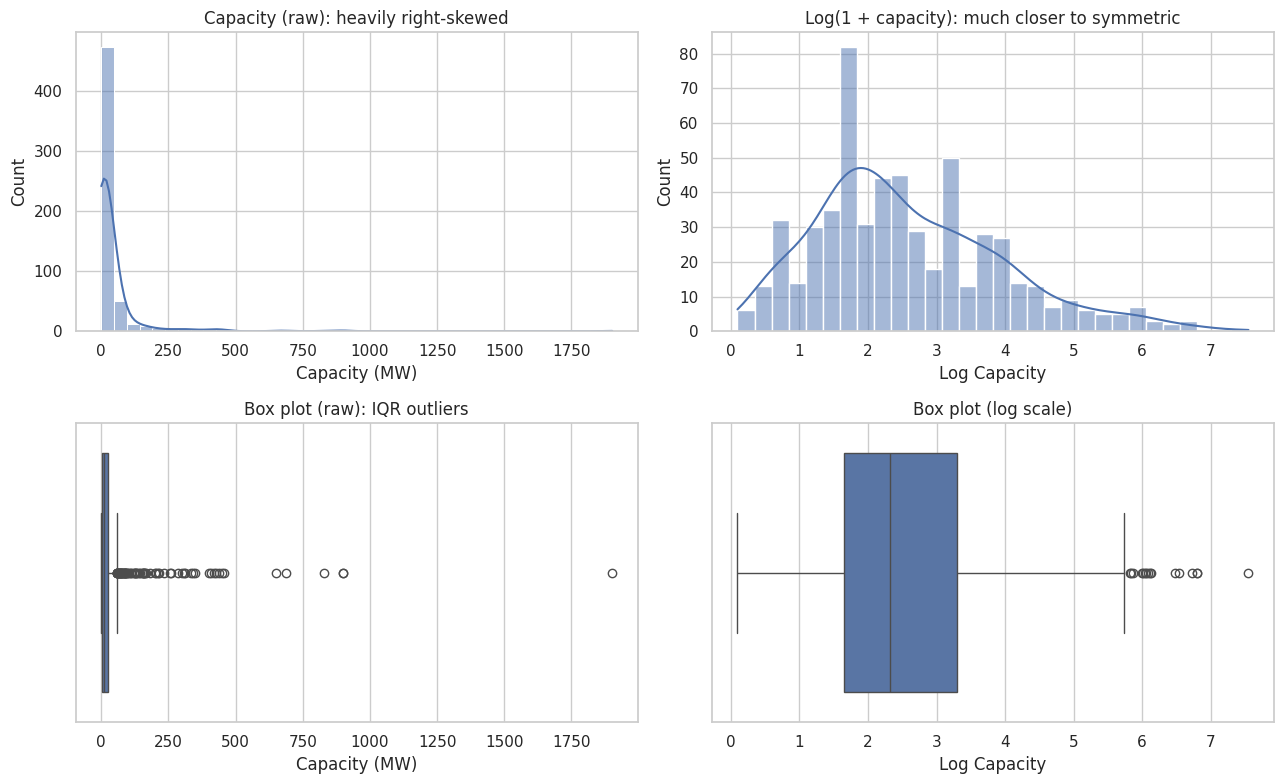

In [11]:
df["Log Capacity"] = np.log1p(df["Capacity (MW)"])

print(f"Skewness before log transform: {df['Capacity (MW)'].skew():.2f}")
print(f"Skewness after  log transform: {df['Log Capacity'].skew():.2f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(df["Capacity (MW)"], bins=40, kde=True, ax=axes[0, 0]).set_title("Capacity (raw): heavily right-skewed")
sns.histplot(df["Log Capacity"], bins=30, kde=True, ax=axes[0, 1]).set_title("Log(1 + capacity): much closer to symmetric")
sns.boxplot(x=df["Capacity (MW)"], ax=axes[1, 0]).set_title("Box plot (raw): IQR outliers")
sns.boxplot(x=df["Log Capacity"], ax=axes[1, 1]).set_title("Box plot (log scale)")
save_fig("01_outlier_treatment")

### 2.5 Feature engineering

New columns built from domain knowledge:

| Feature | Meaning |
|---|---|
| `Capacity Category` | Small (<=10 MW), Medium (10-50), Large (50-100), Very Large (>100) |
| `Province Name` | Official name for each province number |
| `Is NEA Promoter` | 1 if the promoter is the state utility, Nepal Electricity Authority |
| `Is Storage Project` | 1 if the project name mentions "storage" (reservoir-type scheme) |
| `Issue Year (AD approx)`, `License Term (years)` | From section 2.3 |

In [12]:
CATEGORY_LABELS = ["Small (10 MW or less)", "Medium (10-50 MW)", "Large (50-100 MW)", "Very Large (above 100 MW)"]
df["Capacity Category"] = pd.cut(
    df["Capacity (MW)"], bins=[-np.inf, 10, 50, 100, np.inf],
    labels=CATEGORY_LABELS, right=True, ordered=True,
)

PROVINCE_NAMES = {
    "Province 1": "Koshi", "Province 3": "Bagmati", "Province 4": "Gandaki",
    "Province 5": "Lumbini", "Province 6": "Karnali", "Province 7": "Sudurpashchim",
}
df["Province Name"] = df["Province"].map(PROVINCE_NAMES)
df["Is NEA Promoter"] = df["Promoter"].str.contains("Nepal Electricity Authority", case=False, na=False).astype(int)
df["Is Storage Project"] = df["Project"].str.contains("storage", case=False, na=False).astype(int)

display(df["Capacity Category"].value_counts().sort_index().to_frame("Records"))
print("NEA-promoted records:", df["Is NEA Promoter"].sum(), "| Storage projects:", df["Is Storage Project"].sum())
print("Unmapped provinces:", int(df["Province Name"].isna().sum()))

,Records
Capacity Category,
Small (10 MW or less),315
Medium (10-50 MW),169
Large (50-100 MW),42
Very Large (above 100 MW),46


NEA-promoted records: 28 | Storage projects: 6
Unmapped provinces: 0


### 2.6 Encode categorical variables and scale numeric features

* **One-hot encoding** for nominal variables with few categories (`License Type`, `Province`).
* **Ordinal encoding** for `Capacity Category`, which has a natural order.
* **Standard scaling** (mean 0, std 1) for numeric features, so that capacity, coordinates and years are comparable
  for distance-based or regularised models.
* High-cardinality text columns (project, municipality, river, promoter, address, district) are dropped from the
  model-ready table; they are identifiers rather than useful numeric features.

In [13]:
df_model = df.copy()
df_model["Capacity Category (ordinal)"] = df_model["Capacity Category"].cat.codes   # 0 = Small ... 3 = Very Large

# Missing numeric values (only in date-derived columns) -> median, used for modelling only
for col in ["Issue Year (BS)", "Issue Year (AD approx)", "License Term (years)"]:
    df_model[col] = df_model[col].fillna(df_model[col].median())

# One-hot encoding
df_model = pd.get_dummies(df_model, columns=["License Type", "Province"], dtype=int)

# Keep only numeric / encoded columns
DROP_TEXT = ["Project", "Province Name", "District", "Municipality", "River", "Lic No", "Issue Date",
             "Validity", "Promoter", "Address", "Capacity Category"]
df_model = df_model.drop(columns=DROP_TEXT)
df_model["Is Capacity Outlier"] = df_model["Is Capacity Outlier"].astype(int)

# Standardize continuous features
SCALE_COLS = ["Log Capacity", "Longitude", "Latitude", "Issue Year (BS)", "License Term (years)"]
df_scaled = df_model.copy()
df_scaled[SCALE_COLS] = StandardScaler().fit_transform(df_model[SCALE_COLS])

print("Encoded + scaled table:", df_scaled.shape)
display(df_scaled.head())
print("Mean after scaling:", df_scaled[SCALE_COLS].mean().round(3).to_dict())

Encoded + scaled table: (572, 20)


,Capacity (MW),Longitude,Latitude,Issue Year (BS),Issue Year (AD approx),License Term (years),Is Capacity Outlier,Log Capacity,Is NEA Promoter,Is Storage Project,Capacity Category (ordinal),License Type_Generation,License Type_Operation,License Type_Survey,Province_Province 1,Province_Province 3,Province_Province 4,Province_Province 5,Province_Province 6,Province_Province 7
0,13.942,-2.299322,2.930132,0.328511,2016.0,-0.828777,0,0.099719,0,0,1,0,0,1,0,0,0,0,0,1
1,21.000,0.709456,-1.064313,0.534551,2017.0,-0.828777,0,0.384948,0,0,1,0,0,1,1,0,0,0,0,0
2,180.000,-0.787810,-0.127409,0.534551,2017.0,-0.828777,1,1.938732,1,1,3,0,0,1,0,0,0,1,0,0
3,20.000,-0.084478,0.019962,0.328511,2016.0,-0.828777,0,0.350650,0,0,1,0,0,1,0,0,1,0,0,0
4,9.400,-0.780047,-0.146483,-3.998327,1995.0,2.010228,0,-0.167449,0,0,0,0,1,0,0,0,1,0,0,0


Mean after scaling: {'Log Capacity': 0.0, 'Longitude': -0.0, 'Latitude': -0.0, 'Issue Year (BS)': -0.0, 'License Term (years)': -0.0}


### 2.7 Final validation and export

In [14]:
print("Raw shape:    ", df_raw.shape)
print("Cleaned shape:", df.shape)
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Remaining NaN per column (only in date-derived fields):")
nan_left = df.isnull().sum()
display(nan_left[nan_left > 0].to_frame("NaN"))

df.to_csv(DATA_DIR / "nepal_hydropower_cleaned.csv", index=False)
df_scaled.to_csv(DATA_DIR / "nepal_hydropower_model_ready.csv", index=False)
print("Saved: nepal_hydropower_cleaned.csv and nepal_hydropower_model_ready.csv in", DATA_DIR.resolve())

Raw shape:     (572, 14)
Cleaned shape: (572, 23)
Exact duplicate rows: 0
Remaining NaN per column (only in date-derived fields):


,NaN
Validity,40
Issue Year (BS),11
Issue Year (AD approx),11
License Term (years),47


Saved: nepal_hydropower_cleaned.csv and nepal_hydropower_model_ready.csv in /content/data


## 3. Exploratory Data Analysis

### 3.1 Descriptive statistics

In [15]:
num_cols = ["Capacity (MW)", "Log Capacity", "Longitude", "Latitude", "Issue Year (AD approx)", "License Term (years)"]
stats = df[num_cols].describe().T
stats["skew"] = df[num_cols].skew()
stats["mode"] = df[num_cols].mode().iloc[0]
display(stats.round(2))

print("Categorical variables:")
display(df[["Province Name", "District", "License Type", "River", "Promoter", "Capacity Category"]].describe().T)

,count,mean,std,min,25%,50%,75%,max,skew,mode
Capacity (MW),572.0,41.91,124.86,0.10,4.20,9.23,26.25,1902.00,8.39,5.00
Log Capacity,572.0,2.57,1.36,0.10,1.65,2.33,3.30,7.55,0.75,1.79
Longitude,572.0,85.12,1.84,80.61,83.86,85.20,86.56,88.15,-0.36,83.42
Latitude,572.0,28.03,0.61,26.78,27.57,28.00,28.36,29.82,0.68,27.46
Issue Year (AD approx),561.0,2014.37,4.90,1994.00,2013.00,2016.00,2017.00,2018.00,-2.80,2017.00
License Term (years),525.0,17.15,17.15,0.00,2.00,3.00,35.00,50.60,0.35,2.00


Categorical variables:


,count,unique,top,freq
Province Name,572,6,Gandaki,182
District,572,54,DOLAKHA,44
License Type,572,3,Survey,311
River,572,315,Seti Khola,11
Promoter,572,511,Nepal Electricity Authority,28
Capacity Category,572,4,Small (10 MW or less),315


In [16]:
cap_stats = df["Capacity (MW)"]
print(f"Mean {cap_stats.mean():.2f} MW | Median {cap_stats.median():.2f} MW | Mode {cap_stats.mode().iloc[0]:.2f} MW")
print(f"Std {cap_stats.std():.2f} | Min {cap_stats.min():.2f} | Max {cap_stats.max():.2f}")

Mean 41.91 MW | Median 9.23 MW | Mode 5.00 MW
Std 124.86 | Min 0.10 | Max 1902.00


### 3.2 Distributions of categorical variables

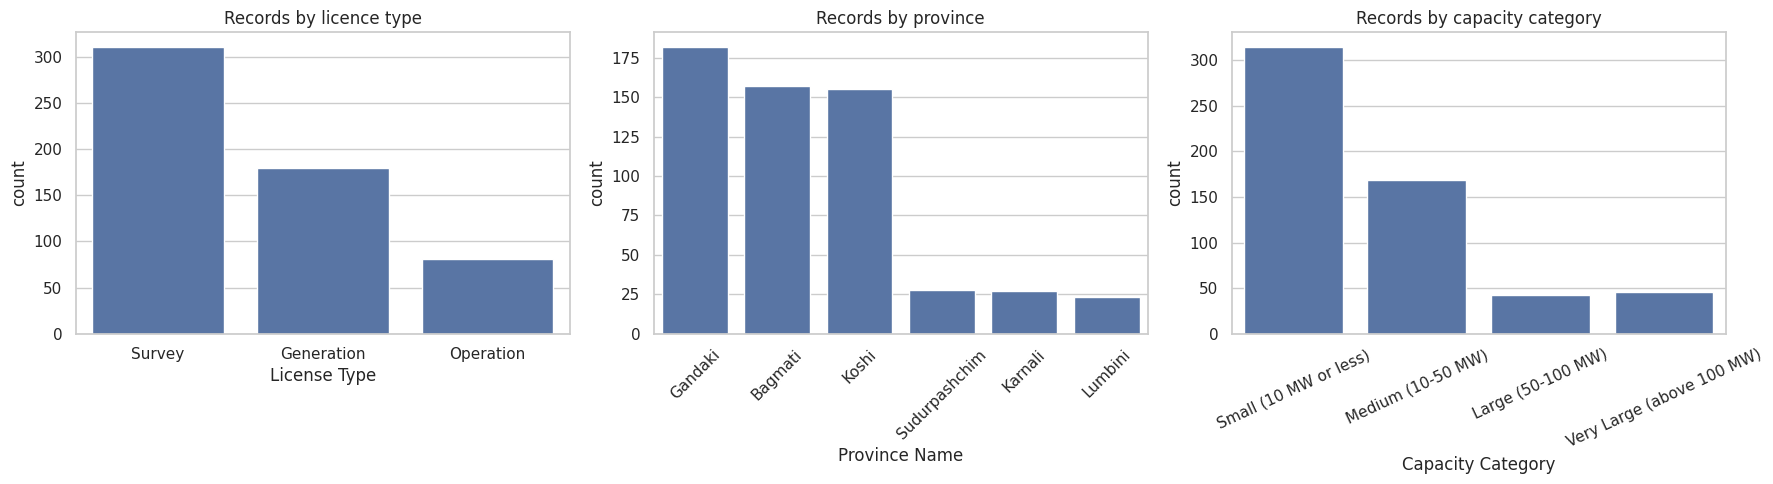

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

order = df["License Type"].value_counts().index
sns.countplot(data=df, x="License Type", order=order, ax=axes[0])
axes[0].set_title("Records by licence type")

order = df["Province Name"].value_counts().index
sns.countplot(data=df, x="Province Name", order=order, ax=axes[1])
axes[1].set_title("Records by province")
axes[1].tick_params(axis="x", rotation=45)

sns.countplot(data=df, x="Capacity Category", order=CATEGORY_LABELS, ax=axes[2])
axes[2].set_title("Records by capacity category")
axes[2].tick_params(axis="x", rotation=25)
save_fig("02_categorical_distributions")

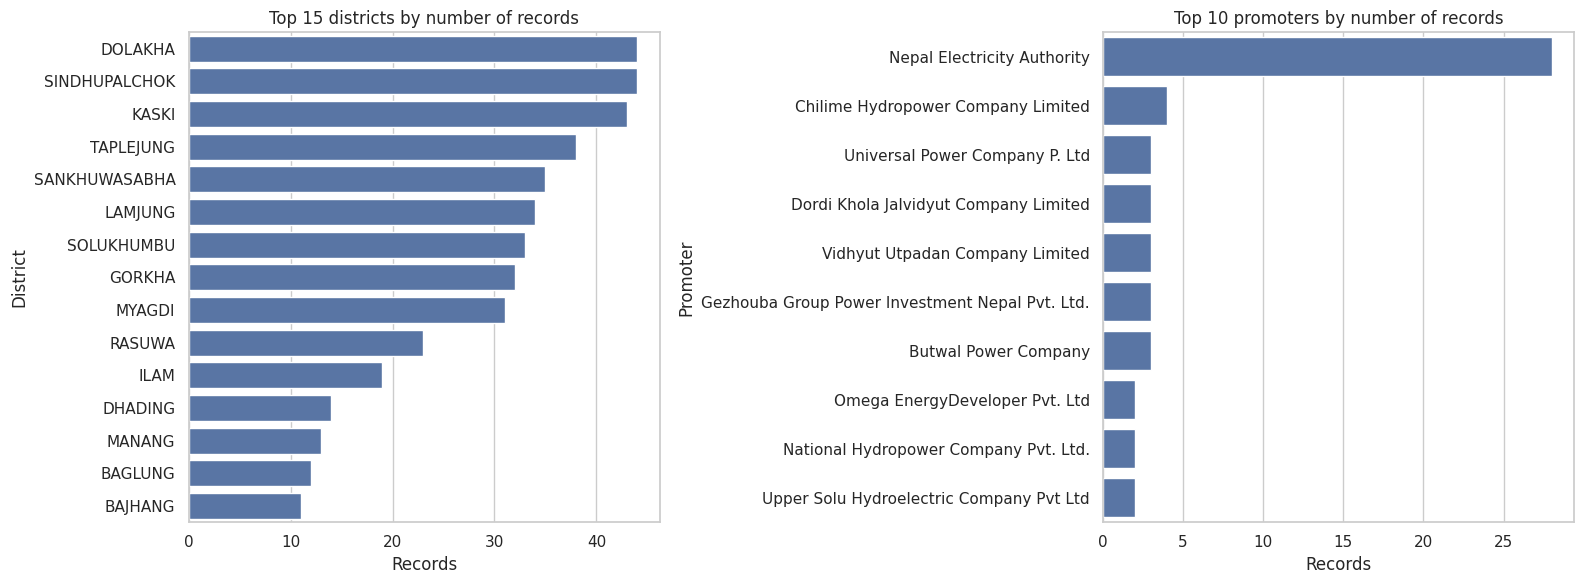

511 distinct promoters for 572 records


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_districts = df["District"].value_counts().head(15)
sns.barplot(x=top_districts.values, y=top_districts.index, ax=axes[0])
axes[0].set_title("Top 15 districts by number of records")
axes[0].set_xlabel("Records")

top_promoters = df["Promoter"].value_counts().head(10)
sns.barplot(x=top_promoters.values, y=top_promoters.index, ax=axes[1])
axes[1].set_title("Top 10 promoters by number of records")
axes[1].set_xlabel("Records")
save_fig("03_top_districts_promoters")

print(f"{df['Promoter'].nunique()} distinct promoters for {len(df)} records")

### 3.3 Capacity by licence type, province and river

> **Note:** *Survey* licences are for projects still being studied, so their capacity is **proposed**, not installed.
> Totals below mix proposed and licensed capacity, so the *Operation* subset is analysed separately.

,count,mean,median,max,sum
License Type,,,,,
Generation,180,27.66,9.56,456.0,4979.43
Operation,81,12.26,4.50,144.0,993.36
Survey,311,57.88,9.96,1902.0,18000.39


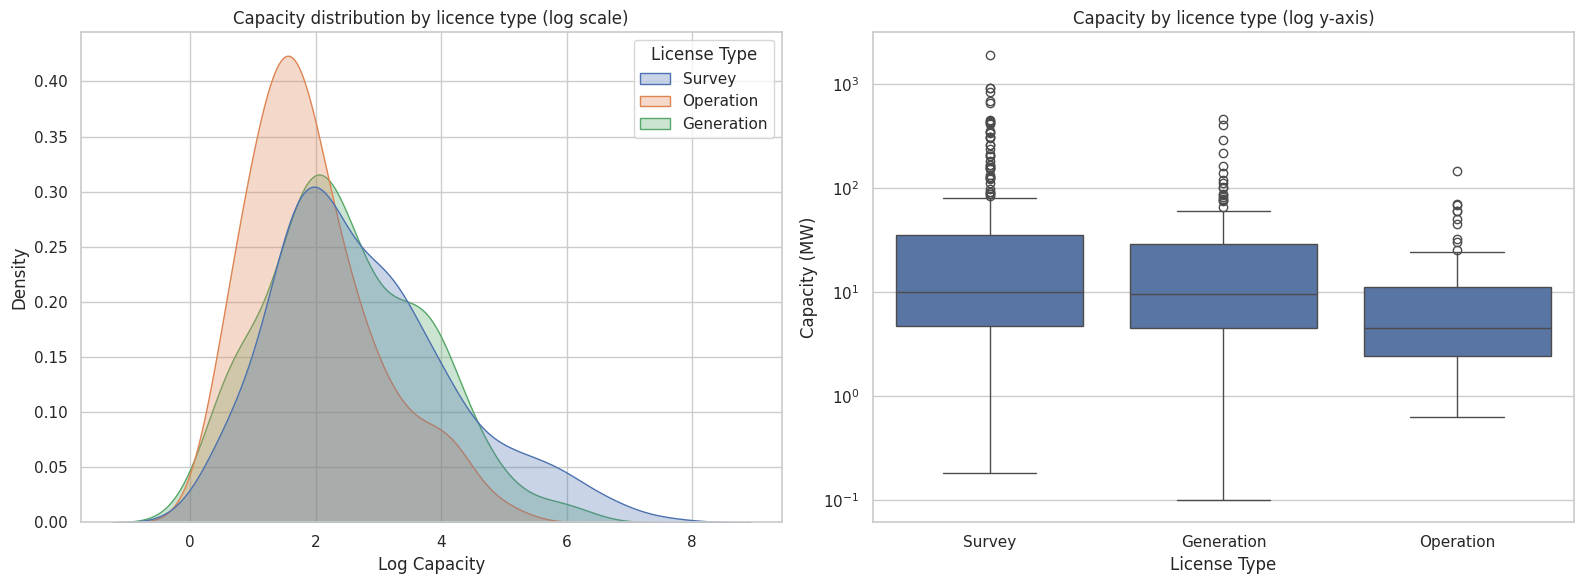

In [19]:
by_license = df.groupby("License Type")["Capacity (MW)"].agg(["count", "mean", "median", "max", "sum"]).round(2)
display(by_license)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.kdeplot(data=df, x="Log Capacity", hue="License Type", common_norm=False, fill=True, alpha=0.3, ax=axes[0])
axes[0].set_title("Capacity distribution by licence type (log scale)")
sns.boxplot(data=df, x="License Type", y="Capacity (MW)", order=["Survey", "Generation", "Operation"], ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Capacity by licence type (log y-axis)")
save_fig("04_capacity_by_license")

,Records,Total_MW,Median_MW,Operating_MW
Province Name,,,,
Gandaki,182,5990.6,9.3,308.9
Koshi,155,5388.0,9.5,120.7
Bagmati,157,4615.9,8.5,340.8
Karnali,27,4234.5,21.0,3.8
Sudurpashchim,28,3227.0,9.2,38.5
Lumbini,23,517.3,4.7,180.7


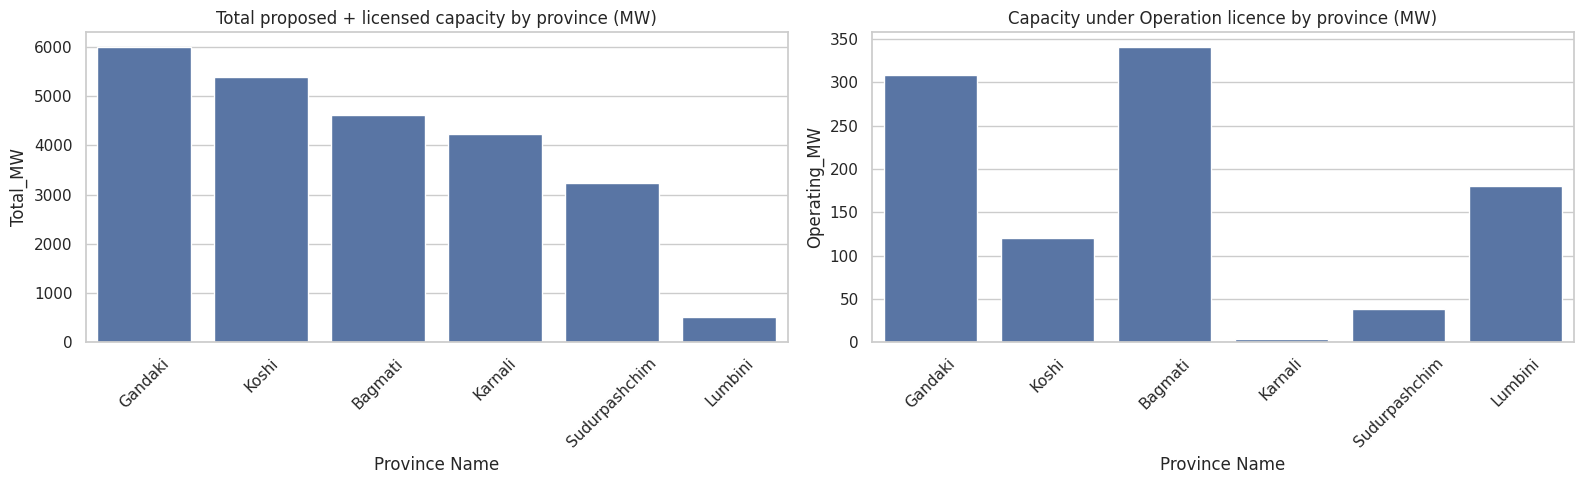

In [20]:
province_summary = (
    df.groupby("Province Name")
      .agg(Records=("Project", "count"), Total_MW=("Capacity (MW)", "sum"), Median_MW=("Capacity (MW)", "median"))
      .sort_values("Total_MW", ascending=False).round(1)
)
province_summary["Operating_MW"] = df[df["License Type"] == "Operation"].groupby("Province Name")["Capacity (MW)"].sum().round(1)
province_summary["Operating_MW"] = province_summary["Operating_MW"].fillna(0)
display(province_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=province_summary.index, y=province_summary["Total_MW"], ax=axes[0])
axes[0].set_title("Total proposed + licensed capacity by province (MW)")
axes[0].tick_params(axis="x", rotation=45)
sns.barplot(x=province_summary.index, y=province_summary["Operating_MW"], ax=axes[1])
axes[1].set_title("Capacity under Operation licence by province (MW)")
axes[1].tick_params(axis="x", rotation=45)
save_fig("05_capacity_by_province")

License Type,Generation,Operation,Survey
Province Name,,,
Bagmati,60,29,68
Gandaki,56,23,103
Karnali,7,1,19
Koshi,44,19,92
Lumbini,4,7,12
Sudurpashchim,9,2,17


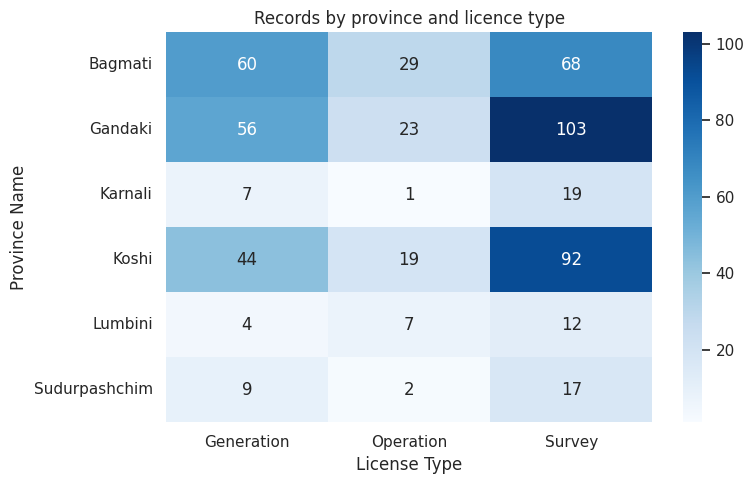

In [21]:
province_license = pd.crosstab(df["Province Name"], df["License Type"])
display(province_license)

plt.figure(figsize=(8, 5))
sns.heatmap(province_license, annot=True, fmt="d", cmap="Blues")
plt.title("Records by province and licence type")
save_fig("06_province_license_heatmap")

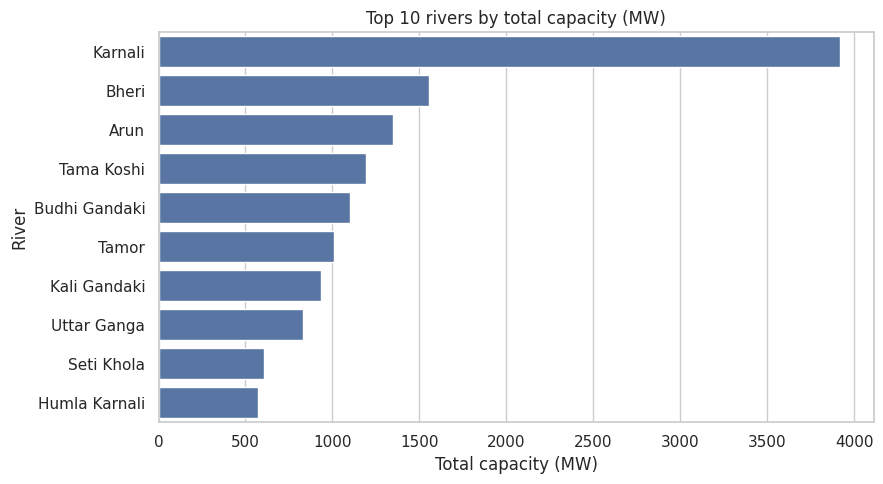

In [22]:
# Rivers with the largest total capacity (river names are not fully standardised in the source)
top_rivers = df.groupby("River")["Capacity (MW)"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_rivers.values, y=top_rivers.index)
plt.title("Top 10 rivers by total capacity (MW)")
plt.xlabel("Total capacity (MW)")
save_fig("07_top_rivers")

### 3.4 Geography and time

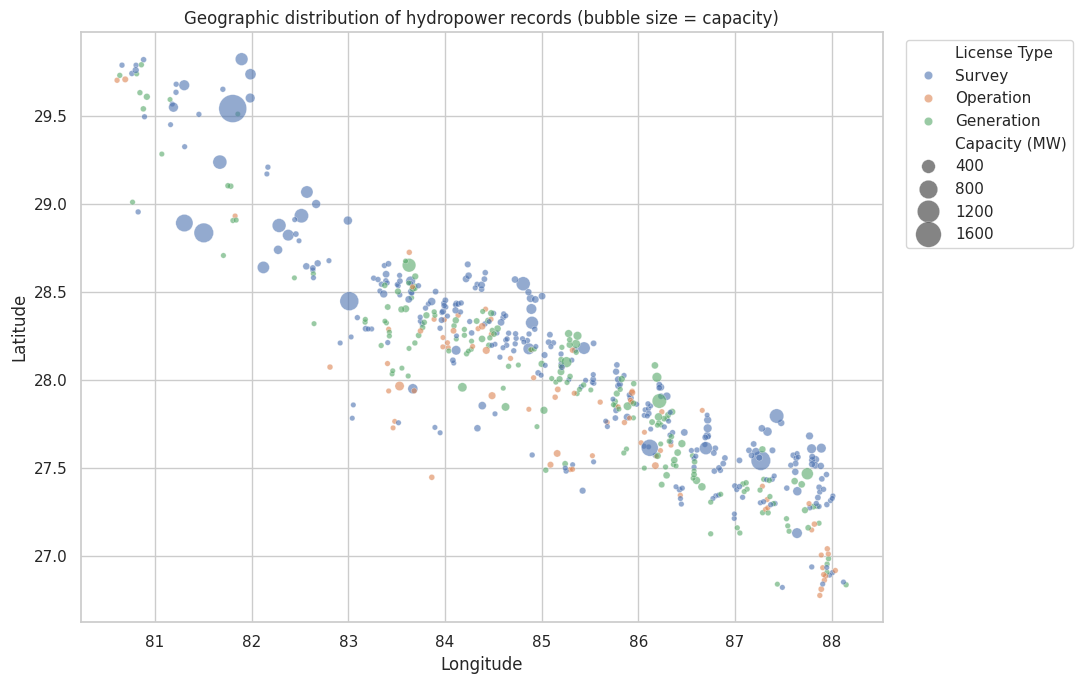

In [23]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df, x="Longitude", y="Latitude", hue="License Type",
    size="Capacity (MW)", sizes=(15, 400), alpha=0.6,
)
plt.title("Geographic distribution of hydropower records (bubble size = capacity)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
save_fig("08_geographic_distribution")

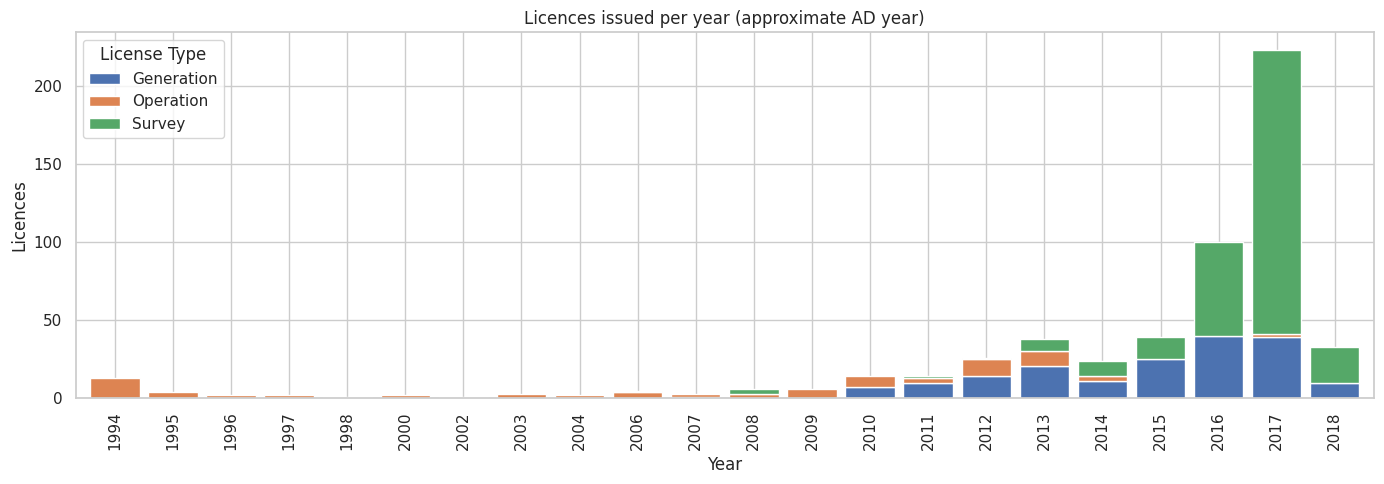

In [24]:
# Licences issued per year (approximate AD year) by licence type
issued = df.dropna(subset=["Issue Year (AD approx)"]).copy()
issued["Issue Year (AD approx)"] = issued["Issue Year (AD approx)"].astype(int)
per_year = pd.crosstab(issued["Issue Year (AD approx)"], issued["License Type"])

per_year.plot(kind="bar", stacked=True, figsize=(14, 5), width=0.85)
plt.title("Licences issued per year (approximate AD year)")
plt.xlabel("Year")
plt.ylabel("Licences")
save_fig("09_licenses_per_year")

### 3.5 Relationships between variables

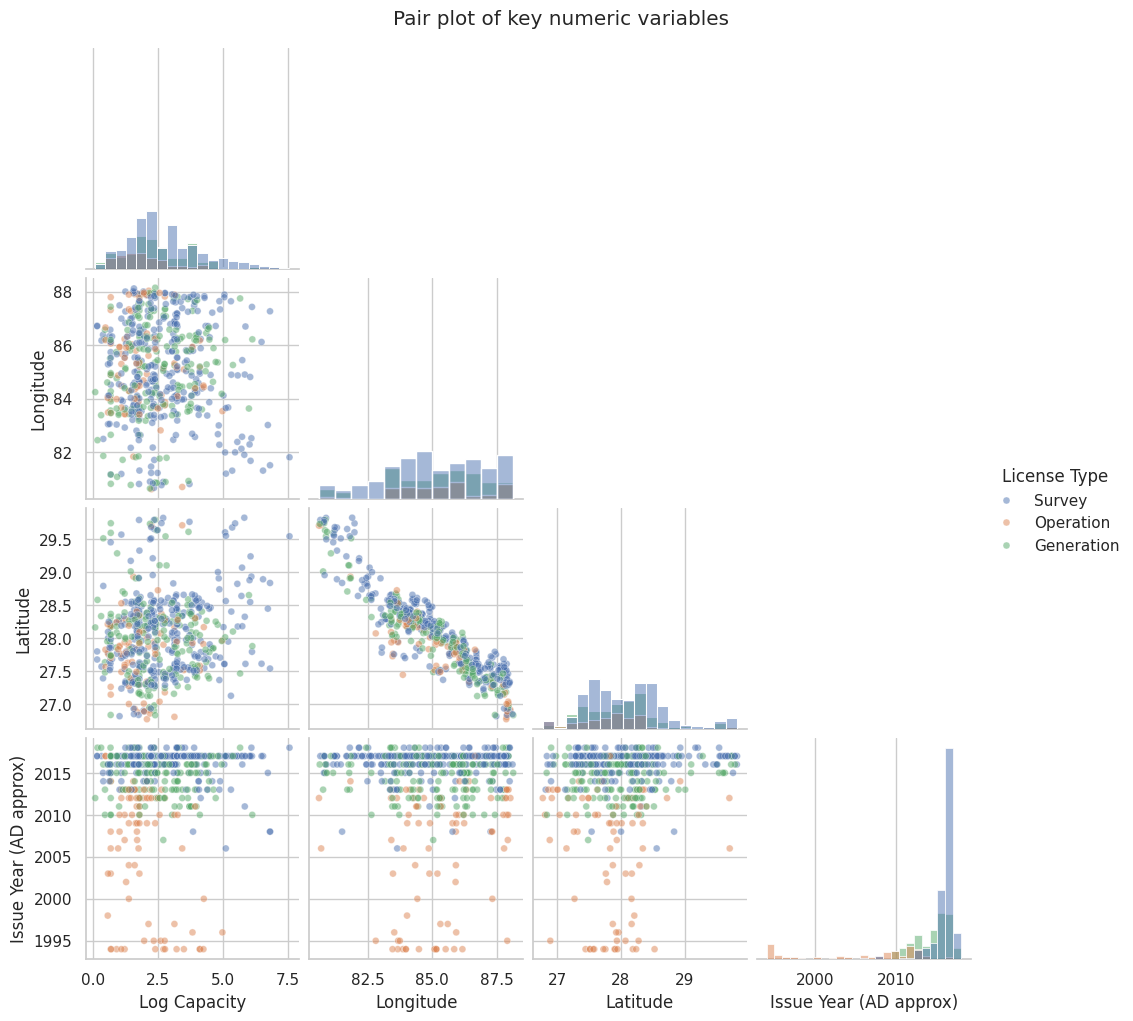

In [25]:
pair_cols = ["Log Capacity", "Longitude", "Latitude", "Issue Year (AD approx)"]
g = sns.pairplot(df[pair_cols + ["License Type"]], hue="License Type", diag_kind="hist",
                 corner=True, plot_kws={"alpha": 0.5, "s": 25})
g.fig.suptitle("Pair plot of key numeric variables", y=1.02)
g.savefig(FIG_DIR / "10_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

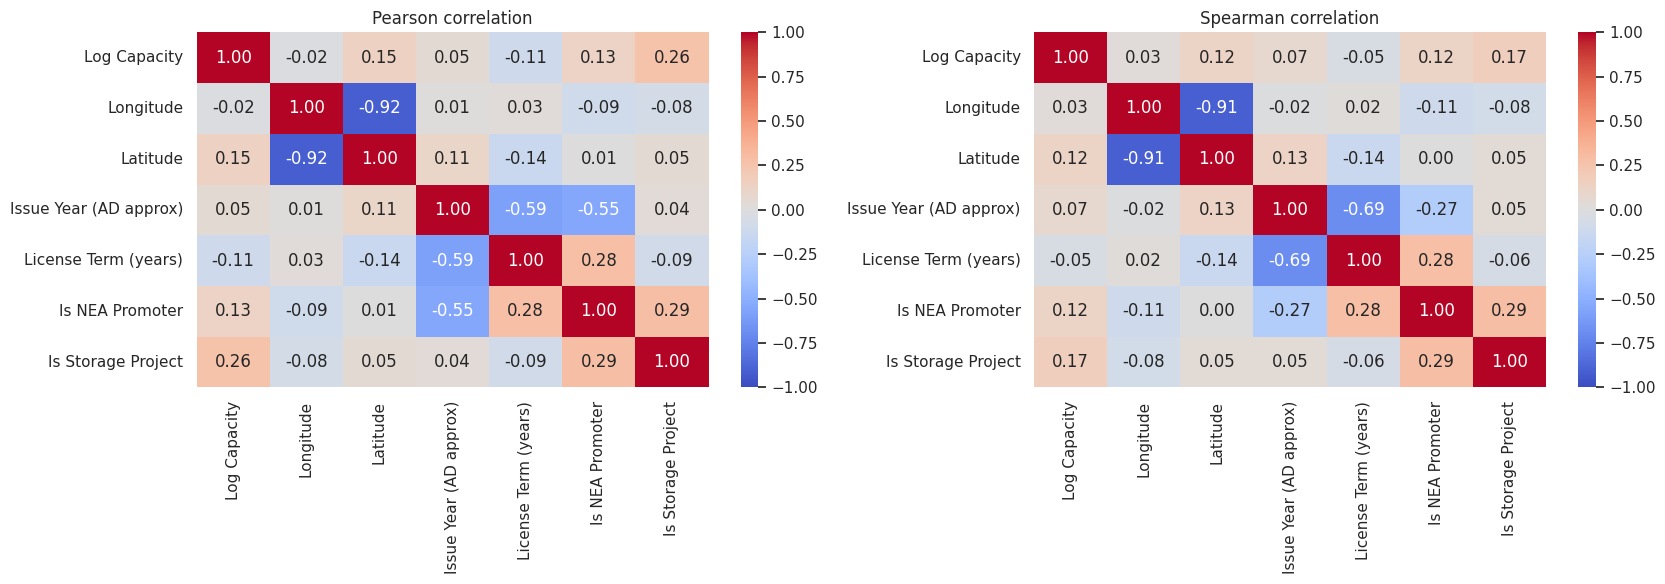

Correlation of each variable with Log Capacity (Spearman):


,rho
License Term (years),-0.045
Longitude,0.025
Issue Year (AD approx),0.073
Latitude,0.118
Is NEA Promoter,0.123
Is Storage Project,0.168


In [26]:
corr_cols = ["Log Capacity", "Longitude", "Latitude", "Issue Year (AD approx)", "License Term (years)",
             "Is NEA Promoter", "Is Storage Project"]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = df[corr_cols].corr(method=method)
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"{method.title()} correlation")
save_fig("11_correlation_heatmaps")

print("Correlation of each variable with Log Capacity (Spearman):")
display(df[corr_cols].corr(method="spearman")["Log Capacity"].drop("Log Capacity").sort_values().round(3).to_frame("rho"))

**Reading the correlations:** the strong negative correlation between longitude and latitude (about -0.92) is just
Nepal's geography, because the country runs from the south-east to the north-west. It is not a meaningful
relationship between project variables. Capacity itself shows only weak correlation with location, so
**location alone does not explain project size**.

## 4. Feature Selection

**Goal:** find which engineered and encoded features carry the most information about project size (`Log Capacity`).

Features derived from capacity itself (`Capacity (MW)`, `Capacity Category (ordinal)`, `Is Capacity Outlier`) are
**excluded to avoid target leakage**. Two complementary methods are used:

* **Mutual information:** captures any (also non-linear) dependency on the target.
* **Random-forest importance:** captures interactions between features.

,Mutual information,Random-forest importance,Average rank
Longitude,0.114,0.302,1.5
License Term (years),0.197,0.109,2.0
Latitude,0.111,0.290,2.5
License Type_Survey,0.043,0.050,5.0
Issue Year (BS),0.038,0.041,6.0
Is Storage Project,0.025,0.074,6.5
Province_Province 6,0.034,0.032,7.5
Is NEA Promoter,0.043,0.008,7.5
Issue Year (AD approx),0.024,0.038,8.5
License Type_Generation,0.029,0.014,9.0


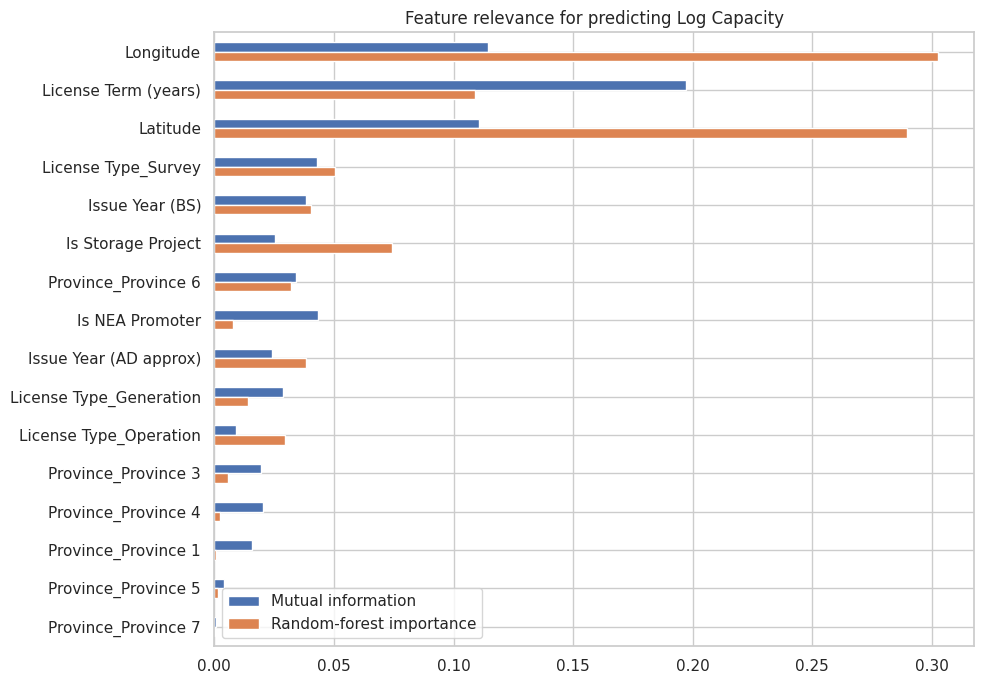

In [27]:
TARGET = "Log Capacity"
LEAKY = ["Capacity (MW)", "Capacity Category (ordinal)", "Is Capacity Outlier", TARGET]

X = df_model.drop(columns=LEAKY)     # unscaled is fine for tree-based methods and mutual information
y = df_model[TARGET]

mi = mutual_info_regression(X, y, random_state=RANDOM_STATE)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1).fit(X, y)

ranking = pd.DataFrame({
    "Mutual information": mi,
    "Random-forest importance": rf.feature_importances_,
}, index=X.columns)
ranking["Average rank"] = ranking.rank(ascending=False).mean(axis=1)
ranking = ranking.sort_values("Average rank")
display(ranking.round(3))

ranking[["Mutual information", "Random-forest importance"]].plot(kind="barh", figsize=(10, 7))
plt.gca().invert_yaxis()
plt.title("Feature relevance for predicting Log Capacity")
save_fig("12_feature_importance")

In [28]:
# Select the top features by average rank
N_SELECT = 6
selected = ranking.head(N_SELECT).index.tolist()
print("Selected features:", selected)

# Honest check: how much of the variation do these features explain?
r2 = cross_val_score(
    RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    X[selected], y, cv=5, scoring="r2",
)
print(f"5-fold cross-validated R2 with selected features: {r2.mean():.2f} (+/- {r2.std():.2f})")

Selected features: ['Longitude', 'License Term (years)', 'Latitude', 'License Type_Survey', 'Issue Year (BS)', 'Is Storage Project']
5-fold cross-validated R2 with selected features: 0.18 (+/- 0.09)


**Interpretation.** Use the cross-validated R-squared above as a reality check: if it is low, project size cannot
be predicted well from licence metadata, location and timing alone. This is expected, because real capacity depends on
river flow, head (drop height) and terrain, which are not in this dataset. Section 5 lists the variables that would
improve a future model. Identifier columns (`Lic No`, `Address`, `Project`) were excluded because they carry no
generalisable signal.

## 5. Key Insights

The numbers below come from the full 572-record dataset.

### Data quality
* The raw file has **no `NaN` values**, but placeholders hide missing data: `Lic No` = `0` (48 rows) or `1_gtd`
  (12 rows), `Address` = `0` (42 rows) and `Validity` = `0/1/0` (40 rows). The 60 "duplicate" licence numbers are
  placeholders, not real duplicates.
* Dates use the **Bikram Sambat** calendar (years like 2073), so they must not be parsed as Gregorian dates.
* There are no exact duplicate rows; 3 project names appear twice.

### Project size
* Capacity is **extremely right-skewed**: mean 41.9 MW against a median of 9.2 MW (most common value 5 MW),
  with a maximum of 1,902 MW (Mugu Karnali Storage HEP).
* **55% of records (315) are Small projects of 10 MW or less**; only 88 records (15%) are above 50 MW.
* 74 records (12.9%) are statistical outliers (above 59.3 MW). Nine of the ten largest projects hold only
  *Survey* licences, so the biggest numbers are proposals rather than built capacity.

### Licensing pipeline
* **54.4% of records (311) are Survey licences**, 31.5% (180) Generation and 14.2% (81) Operation. Most projects are
  therefore still at an early stage.
* Survey projects have a high mean (57.9 MW) but the same typical size as Generation projects (median about 10 MW),
  so the gap in averages comes from a handful of very large proposals. Operation projects are smaller (median 4.5 MW).

### Geography
* **Provinces 4 (Gandaki), 3 (Bagmati) and 1 (Koshi) hold 494 of 572 records (86%)**; Provinces 5, 6 and 7 together have only 78.
  Province 2 does not appear in the data at all.
* Dolakha and Sindhupalchok (44 records each) and Kaski (43) are the most active districts.
* The largest schemes cluster on a few river systems, notably the **Karnali** (four of the top ten), Arun and
  Tama Koshi.
* Capacity has only weak correlation with coordinates (0.18 with latitude, -0.13 with longitude); the -0.92
  correlation between latitude and longitude reflects Nepal's shape, not a project relationship.

### Promoters
* Development is **fragmented**: there are 511 distinct promoters for 572 records. Nepal Electricity Authority
  leads with 28 records, and no private promoter exceeds 4.

### Recommendations
1. **Report medians and categories, not just means**, because averages are dominated by a few giant proposals.
2. **Track the Survey-to-Generation-to-Operation conversion rate**, since over half of the pipeline is still at survey stage.
3. **Look at the under-represented provinces (5, 6, 7)** as potential growth areas, and investigate why Province 2 is absent.
4. **Fix data capture**: replace placeholders with true blanks, store dates in one calendar, and standardise river names.
5. **Add physical variables** (river discharge, head, catchment area) to build a capacity model that works.

In [29]:
# Recompute the headline numbers directly from the data so the insights above can be verified
n = len(df)
print(f"Records: {n}")
print(f"Median / mean capacity: {df['Capacity (MW)'].median():.2f} / {df['Capacity (MW)'].mean():.2f} MW")
print(f"Small projects (<=10 MW): {(df['Capacity Category'] == CATEGORY_LABELS[0]).mean():.1%}")
print(f"Outliers: {df['Is Capacity Outlier'].mean():.1%}")
print("Licence type share:\n", (df['License Type'].value_counts(normalize=True) * 100).round(1).to_string())
top3 = df["Province"].value_counts().head(3)
print(f"\nTop-3 provinces ({', '.join(top3.index)}): {top3.sum()} records = {top3.sum() / n:.1%}")
print("Survey among the 10 largest projects:", int((df.nlargest(10, 'Capacity (MW)')['License Type'] == 'Survey').sum()), "of 10")
print("Distinct promoters:", df["Promoter"].nunique())

Records: 572
Median / mean capacity: 9.23 / 41.91 MW
Small projects (<=10 MW): 55.1%
Outliers: 12.9%
Licence type share:
 License Type
Survey        54.4
Generation    31.5
Operation     14.2

Top-3 provinces (Province 4, Province 3, Province 1): 494 records = 86.4%
Survey among the 10 largest projects: 9 of 10
Distinct promoters: 511


## 6. Limitations and Next Steps

* The dataset is a **licence register snapshot**: it has no generation output, commissioning dates or project status
  beyond the licence type, so conclusions are about the licensing pipeline rather than energy produced.
* Survey-stage capacity is a proposal and may never be built.
* The AD year is approximate (BS - 57), and the validity field was unusable for 40 records.
* Next steps: enrich the data with river-flow and terrain data, link licences over time to measure conversion
  from Survey to Operation, and build an interactive dashboard (for example Streamlit).